In [58]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [59]:
df = pd.read_csv("real_estate_dataset.csv")


In [60]:
df.head()

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  500 non-null    int64  
 1   Square_Feet         500 non-null    float64
 2   Num_Bedrooms        500 non-null    int64  
 3   Num_Bathrooms       500 non-null    int64  
 4   Num_Floors          500 non-null    int64  
 5   Year_Built          500 non-null    int64  
 6   Has_Garden          500 non-null    int64  
 7   Has_Pool            500 non-null    int64  
 8   Garage_Size         500 non-null    int64  
 9   Location_Score      500 non-null    float64
 10  Distance_to_Center  500 non-null    float64
 11  Price               500 non-null    float64
dtypes: float64(4), int64(8)
memory usage: 47.0 KB


In [62]:
df.describe()

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,174.640428,2.958000,1.976000,1.964000,1957.604000,0.536000,0.492000,30.174000,5.164410,10.469641,582209.629529
std,144.481833,74.672102,1.440968,0.820225,0.802491,35.491781,0.499202,0.500437,11.582575,2.853489,5.588197,122273.390345
min,1.000000,51.265396,1.000000,1.000000,1.000000,1900.000000,0.000000,0.000000,10.000000,0.004428,0.062818,276892.470136
25%,125.750000,110.319923,2.000000,1.000000,1.000000,1926.000000,0.000000,0.000000,20.000000,2.760650,6.066754,503080.344140
50%,250.500000,178.290937,3.000000,2.000000,2.000000,1959.000000,1.000000,0.000000,30.000000,5.206518,10.886066,574724.113347
75%,375.250000,239.031220,4.000000,3.000000,3.000000,1988.000000,1.000000,1.000000,41.000000,7.732933,15.072590,665942.301274
max,500.000000,298.241199,5.000000,3.000000,3.000000,2022.000000,1.000000,1.000000,49.000000,9.995439,19.927966,960678.274291


In [63]:
df.isnull().sum()

ID                    0
Square_Feet           0
Num_Bedrooms          0
Num_Bathrooms         0
Num_Floors            0
Year_Built            0
Has_Garden            0
Has_Pool              0
Garage_Size           0
Location_Score        0
Distance_to_Center    0
Price                 0
dtype: int64

In [64]:
df.duplicated().sum()

np.int64(0)

In [65]:
df.dtypes

ID                      int64
Square_Feet           float64
Num_Bedrooms            int64
Num_Bathrooms           int64
Num_Floors              int64
Year_Built              int64
Has_Garden              int64
Has_Pool                int64
Garage_Size             int64
Location_Score        float64
Distance_to_Center    float64
Price                 float64
dtype: object

<Axes: xlabel='Price'>

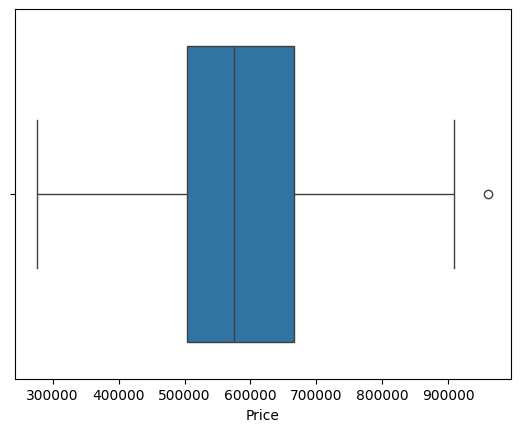

In [66]:
import seaborn as sns

sns.boxplot(x=df["Price"])

<Axes: xlabel='Distance_to_Center'>

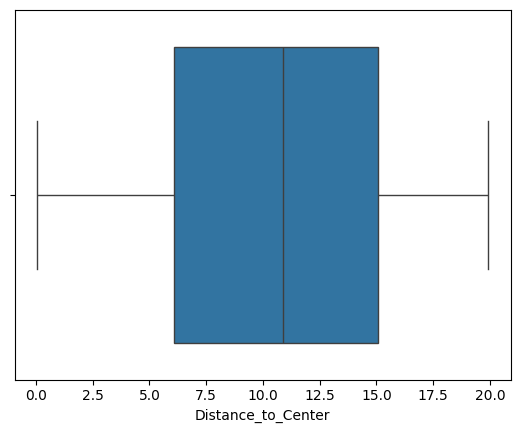

In [67]:
sns.boxplot(x=df["Distance_to_Center"])

<Axes: xlabel='Location_Score'>

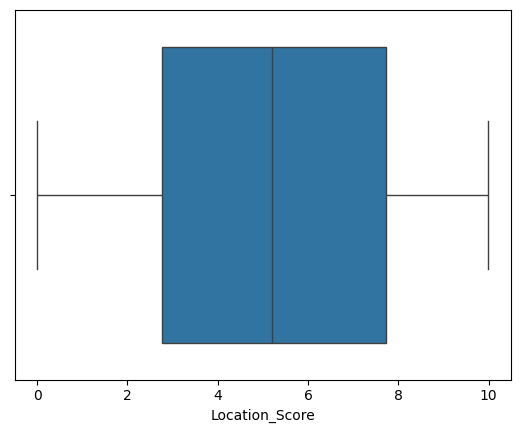

In [68]:
sns.boxplot(x=df["Location_Score"])

<Axes: xlabel='Garage_Size'>

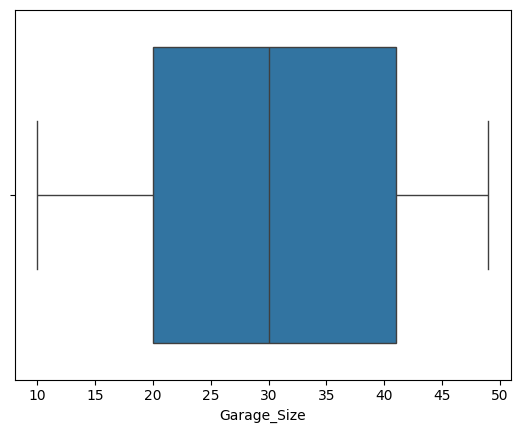

In [69]:
sns.boxplot(x=df["Garage_Size"])

<Axes: xlabel='Has_Pool'>

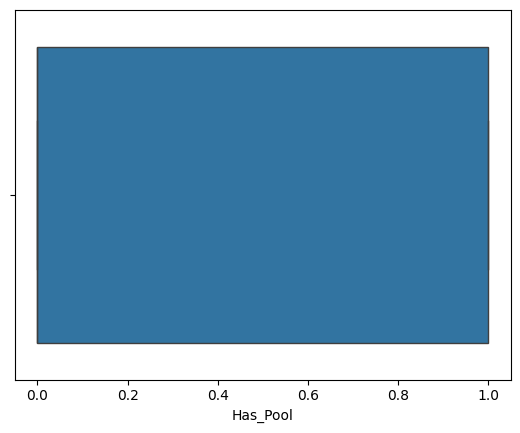

In [70]:
sns.boxplot(x=df["Has_Pool"])

<Axes: xlabel='Has_Garden'>

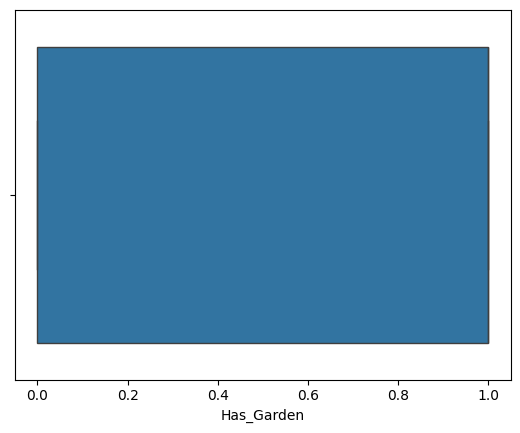

In [71]:
sns.boxplot(x=df["Has_Garden"])

<Axes: xlabel='Year_Built'>

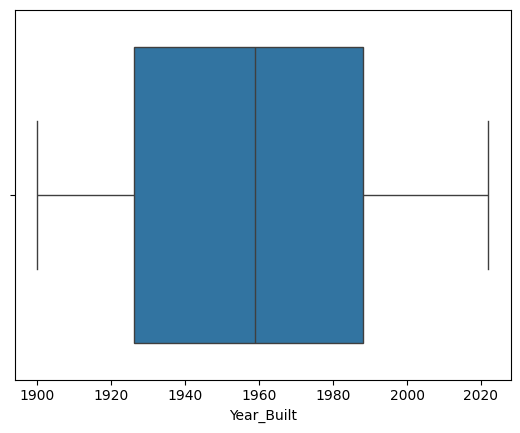

In [72]:
sns.boxplot(x=df["Year_Built"])

In [73]:
print(df['Price'].corr(df['Square_Feet']))

0.5586036660836261


In [74]:
# Price vs Num_Bedrooms
print(df['Price'].corr(df['Num_Bedrooms']))

0.563972875831788


In [75]:
print(df['Price'].corr(df['Square_Feet']))

0.5586036660836261


In [76]:
print(df['Price'].corr(df['Num_Bedrooms']))

0.563972875831788


In [77]:
print(df['Price'].corr(df['Num_Bathrooms']))

0.1566887646845244


In [78]:
print(df['Price'].corr(df['Num_Floors']))

0.177435030705617


In [79]:
print(df['Price'].corr(df['Year_Built']))

0.41829258964064686


In [80]:
print(df['Price'].corr(df['Garage_Size']))

0.032100373543420026


In [81]:
print(df['Price'].corr(df['Location_Score']))

0.07132624835071448


In [82]:
print(df['Price'].corr(df['Distance_to_Center']))

0.0007304592586692374


In [83]:
from scipy.stats import ttest_ind

# Houses with swimming pool
pool_price = df[df['Has_Pool'] == 1]['Price']

# Houses without swimming pool
no_pool_price = df[df['Has_Pool'] == 0]['Price']

# T-test
t_stat, p_value = ttest_ind(
    pool_price,
    no_pool_price,
    nan_policy='omit'
)

print("Price vs Swimming Pool")
print("T-statistic =", t_stat)
print("P-value =", p_value)

if p_value < 0.05:
    print("Reject H0: Swimming pool has a significant effect on house price.")
else:
    print("Fail to Reject H0: Swimming pool has no significant effect on house price.")

Price vs Swimming Pool
T-statistic = 3.0767219401426575
P-value = 0.0022080904378804825
Reject H0: Swimming pool has a significant effect on house price.


In [110]:
garden_price = df[df['Has_Garden'] == 1]['Price']
no_garden_price = df[df['Has_Garden'] == 0]['Price']

print("P-value =", p_value)

if p_value < 0.05:
    print("Reject H0: Garden has a significant effect on house price.")
else:
    print("Fail to Reject H0: Garden has no significant effect on house price.")

P-value = 0.014569918109934552
Reject H0: Garden has a significant effect on house price.


In [85]:
x = df.drop(['Price'], axis=1)
y = df['Price']

In [86]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [87]:
x_scaler = StandardScaler()
x_train_scaled = x_scaler.fit_transform(x_train)
x_test_scaled = x_scaler.transform(x_test)

In [88]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(x_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [89]:
y_pred=model.predict(x_test_scaled)

In [90]:
print("linear regression")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

linear regression
MAE: 16900.083322544022
MSE: 438713006.7476907
R2 Score: 0.9708338115676791


In [91]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

# model
ridge=Ridge()
param={
    'alpha':[0.01,0.1,1,10,100]
}
random=RandomizedSearchCV(
    estimator=ridge,
    param_distributions=param,
    n_iter=5,
    cv=5,
    random_state=42,
    n_jobs=-1
)
random.fit(x_train_scaled, y_train)
best_model=random.best_estimator_
y_pred=best_model.predict(x_test_scaled)
print("Best Parameters:",random.best_params_)
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

Best Parameters: {'alpha': 0.1}
MAE: 16907.919326976975
MSE: 439094180.3192261
R2 Score: 0.970808470672739


In [92]:
from sklearn.linear_model import Ridge
# model
model=Ridge(alpha=0.1)
# training
model.fit(x_train_scaled,y_train)

# prediction
y_pred=model.predict(x_test_scaled)

# evaluation
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

MAE: 16907.919326976975
MSE: 439094180.3192261
R2 Score: 0.970808470672739


In [93]:
#DecisionTreeRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

model=DecisionTreeRegressor()
model.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [94]:
y_pred=model.predict(x_test)


print("decision tree")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

decision tree
MAE: 58046.20311113523
MSE: 5558069791.914839
R2 Score: 0.6304925808497646


In [95]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
dt=DecisionTreeRegressor()
param={
    'max_depth':[5,10,15,20,None],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4]
}
random=RandomizedSearchCV(
    estimator=dt,
    param_distributions=param,
    n_iter=10,
    cv=5,
    random_state=42,
    n_jobs=-1
)
random.fit(x_train,y_train)
best_model=random.best_estimator_
y_pred=best_model.predict(x_test)
print("Best Parameters:",random.best_params_)
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

Best Parameters: {'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': None}
MAE: 56070.44293691517
MSE: 5077218034.884944
R2 Score: 0.6624602060120892


In [96]:
#after DecisionTreeRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
model=DecisionTreeRegressor(min_samples_split = 10, min_samples_leaf = 2, max_depth = None)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
print("decision tree")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

decision tree
MAE: 56070.44293691518
MSE: 5077218034.884945
R2 Score: 0.662460206012089


In [97]:
from sklearn.ensemble import RandomForestRegressor

model=RandomForestRegressor()

model.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [98]:
y_pred=model.predict(x_test)

print("randomforest")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

randomforest
MAE: 44623.55147755511
MSE: 2930148410.264396
R2 Score: 0.8052000753248995


In [99]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

# Fit RandomizedSearchCV, not rf
random_search.fit(x_train, y_train)

# Get best model
best_model = random_search.best_estimator_

# Predict
y_pred = best_model.predict(x_test)

# Results
print("Best Parameters:", random_search.best_params_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 30}
MAE: 43321.0394778189
MSE: 2786257704.713473
R2 Score: 0.8147661090809295


In [100]:
from sklearn.ensemble import RandomForestRegressor

model=RandomForestRegressor(n_estimators = 200, min_samples_split = 2, min_samples_leaf = 1, max_depth = 30)

model.fit(x_train,y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,30
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [101]:
y_pred=model.predict(x_test_scaled)

print("randomforest")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

randomforest
MAE: 223700.99627347133
MSE: 63251948136.64261
R2 Score: -3.2050684837016634


C:\Users\meenu\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [116]:
from xgboost import XGBRegressor
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

# Train
model.fit(x_train, y_train)

# Prediction
y_pred = model.predict(x_test)

# Evaluation
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

MAE : 34793.13612243424
MSE : 1822376946.6990955
R² Score: 0.8788461053020209


In [112]:
#KNNeighborsRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
model=KNeighborsRegressor()
model.fit(x_train_scaled,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [113]:
y_pred=model.predict(x_test_scaled)

In [114]:
# evaluation
print("knn")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

knn
MAE: 52847.49211309334
MSE: 4727302545.459555
R2 Score: 0.6857230246269885


In [105]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
knn=KNeighborsRegressor()
param={
    'n_neighbors':[3,5,7,9,11],
    'weights':['uniform','distance'],
    'metric':['euclidean','manhattan']
}
random=RandomizedSearchCV(
    estimator=knn,
    param_distributions=param,
    n_iter=10,
    cv=5,
    random_state=42,
    n_jobs=-1
)
random.fit(x_train_scaled,y_train)
best_model=random.best_estimator_
y_pred=best_model.predict(x_test_scaled)
print("Best Parameters:",random.best_params_)
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

Best Parameters: {'weights': 'distance', 'n_neighbors': 7, 'metric': 'euclidean'}
MAE: 50495.85962770344
MSE: 4310759019.88105
R2 Score: 0.7134153582720519


In [106]:
#after KNNeighborsRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
model=KNeighborsRegressor(weights='distance',n_neighbors=7,metric='euclidean')
model.fit(x_train_scaled,y_train)
y_pred=model.predict(x_test_scaled)
# evaluation
print("knn")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

knn
MAE: 50495.85962770344
MSE: 4310759019.88105
R2 Score: 0.7134153582720519


In [107]:
#SVR
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

model=SVR()
model.fit(x_train_scaled,y_train)
y_pred=model.predict(x_test_scaled)
# evaluation
print("svr")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

svr
MAE: 100394.888613483
MSE: 15601543700.03393
R2 Score: -0.037210104080586115


In [108]:
from sklearn.svm import SVR
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
svr=SVR()
param={
    'kernel':['linear','rbf'],
    'C':[0.1,1,10,100],
    'gamma':['scale','auto']
}
random=RandomizedSearchCV(
    estimator=svr,
    param_distributions=param,
    n_iter=10,
    cv=5,
    random_state=42,
    n_jobs=-1
)
random.fit(x_train_scaled,y_train)
best_model=random.best_estimator_
y_pred=best_model.predict(x_test_scaled)
print("Best Parameters:",random.best_params_)
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

Best Parameters: {'kernel': 'linear', 'gamma': 'auto', 'C': 100}
MAE: 78633.76205044166
MSE: 9583672162.170294
R2 Score: 0.36286550921385763


In [109]:
model=SVR(kernel='linear',gamma='auto',C=100)
model.fit(x_train_scaled,y_train)
y_pred=model.predict(x_test_scaled)
# evaluation
print("svr")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

svr
MAE: 78633.76205044166
MSE: 9583672162.170294
R2 Score: 0.36286550921385763


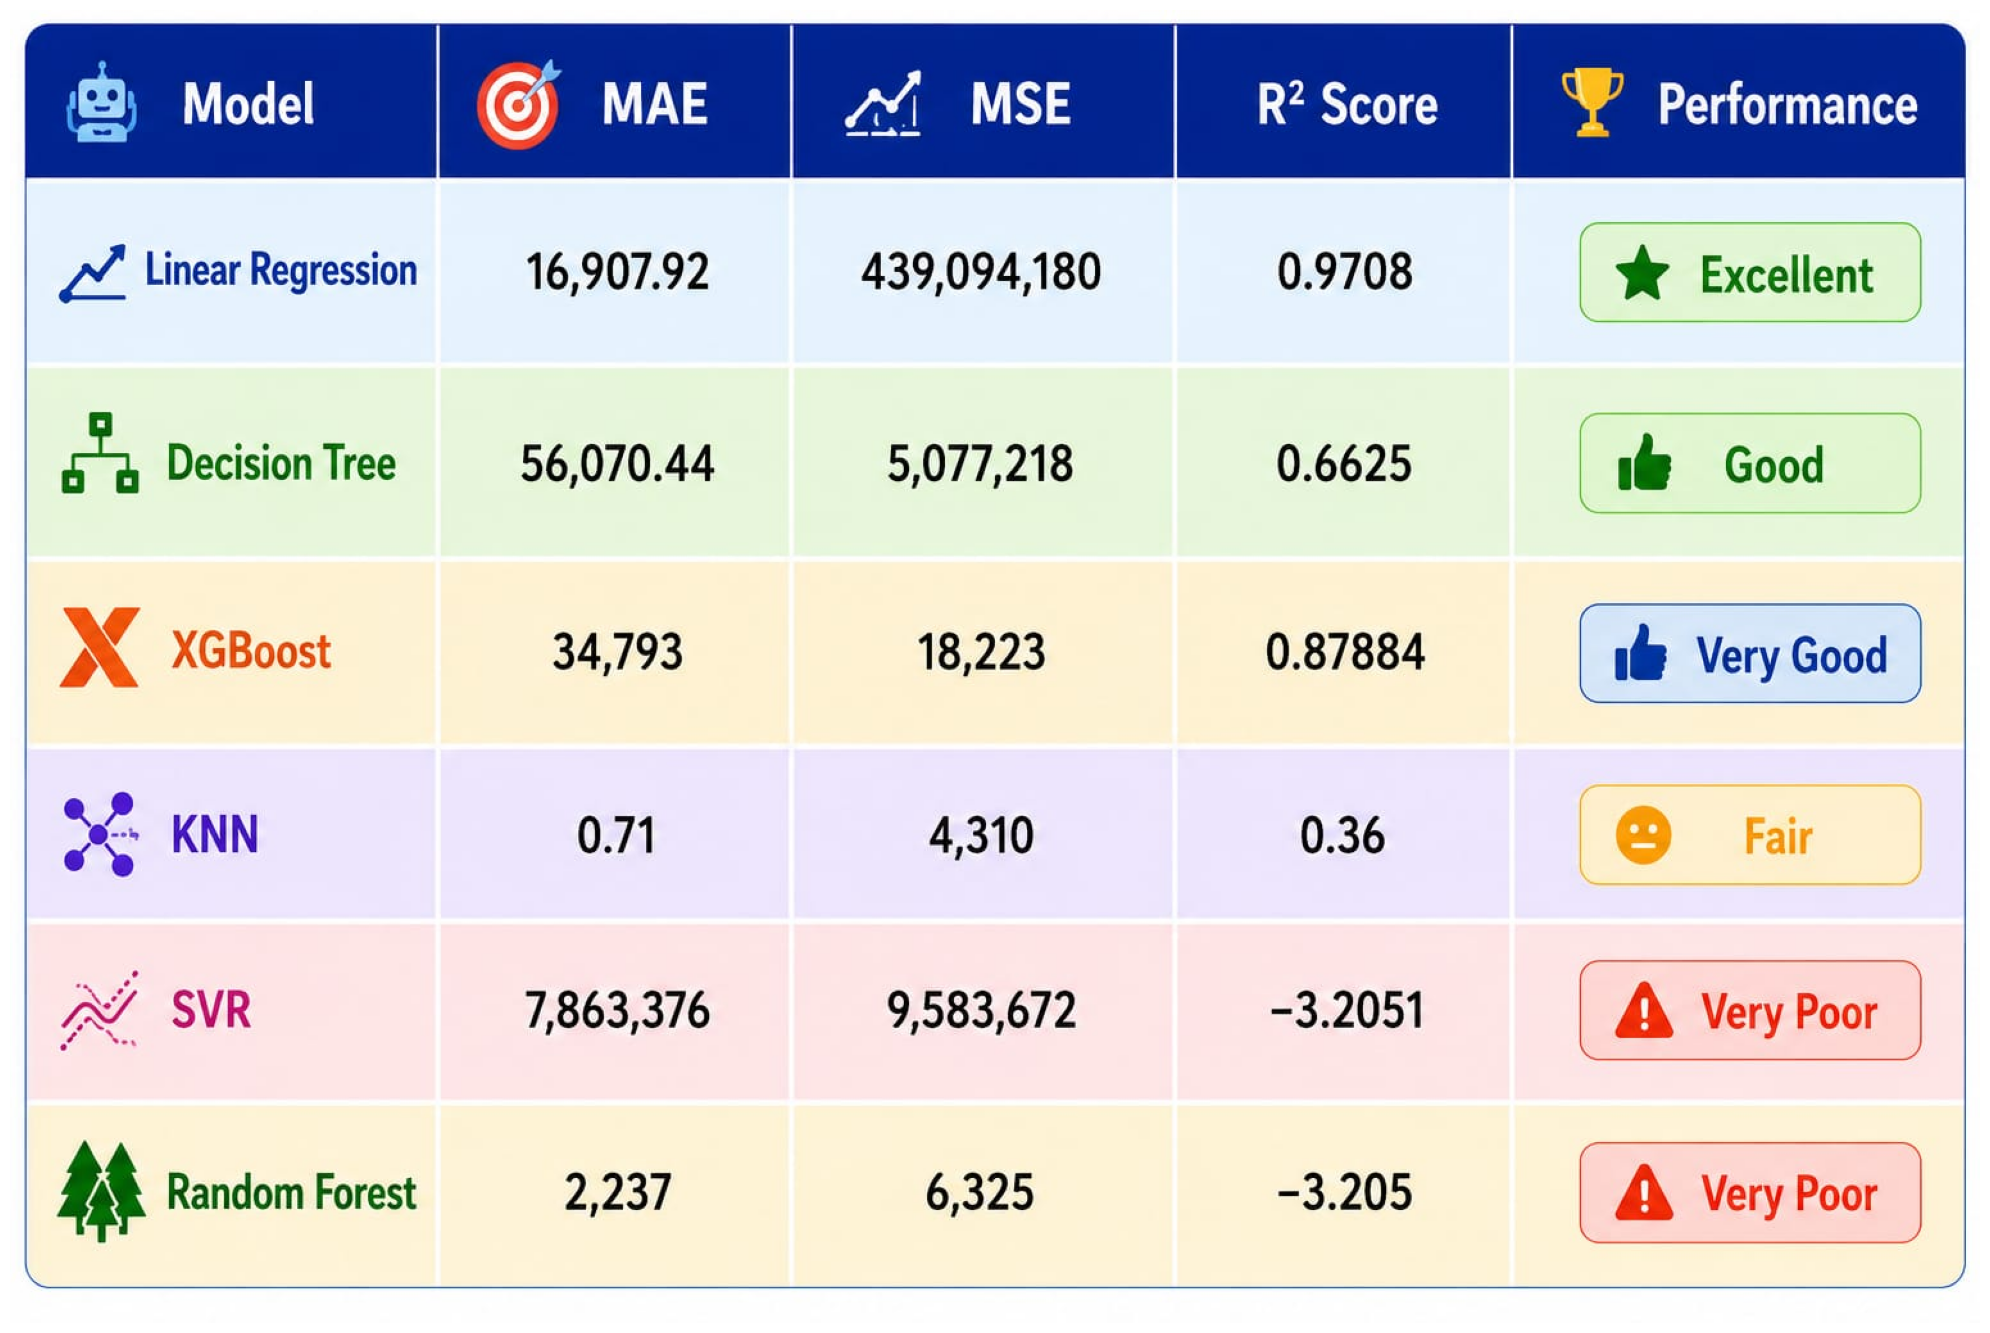

In [118]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("C:/Users/meenu/Downloads/regression image.jpeg")

plt.figure(figsize=(20,15))  # Very large
plt.imshow(img)
plt.axis("off")
plt.tight_layout()
plt.show()